In [5]:
import pandas as pd
import matplotlib.pyplot as plt

summary = pd.read_csv("../results/summary.csv")
per_file = pd.read_csv("../results/results_per_file.csv")
summary

,model,WER,CER,median_time_s,load_time_s
0,tiny,0.524,0.144,1.174,2.260
1,base,0.476,0.102,2.293,2.058
2,small,0.190,0.034,7.372,4.946


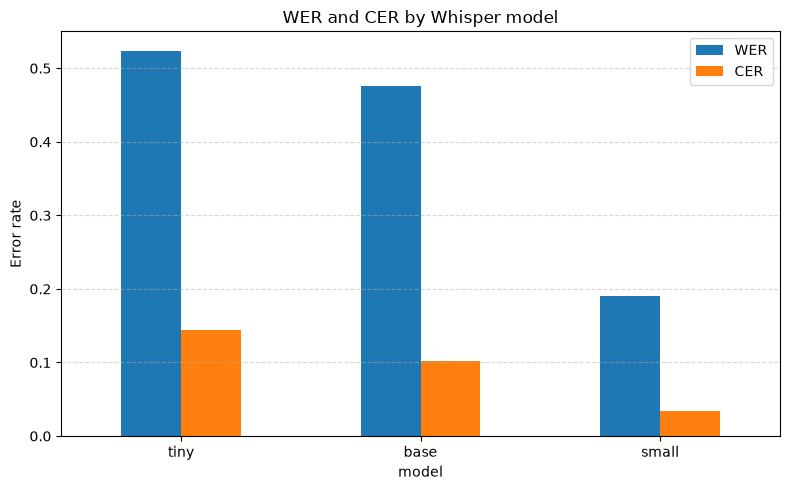

In [6]:
ax = summary.set_index("model")[["WER", "CER"]].plot.bar(figsize=(8, 5), rot=0)
ax.set_title("WER and CER by Whisper model")
ax.set_ylabel("Error rate")
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("../results/wer_cer.png", dpi=150, bbox_inches="tight")
plt.show()

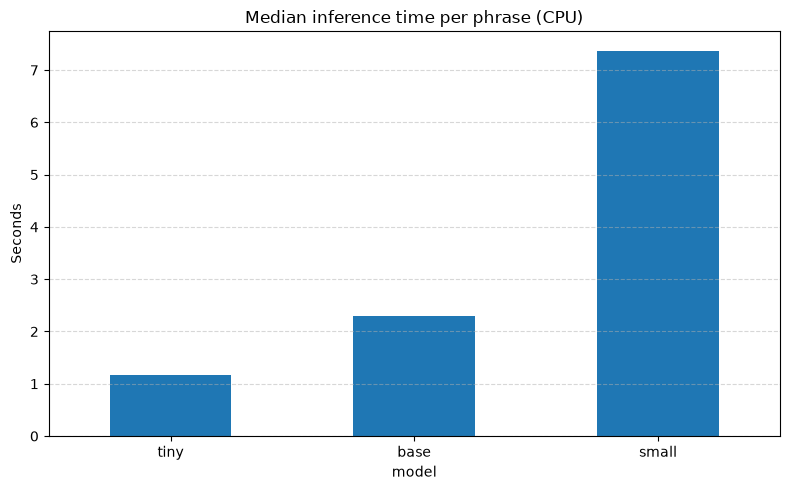

In [7]:
ax = summary.set_index("model")["median_time_s"].plot.bar(figsize=(8, 5), rot=0)
ax.set_title("Median inference time per phrase (CPU)")
ax.set_ylabel("Seconds")
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("../results/time_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

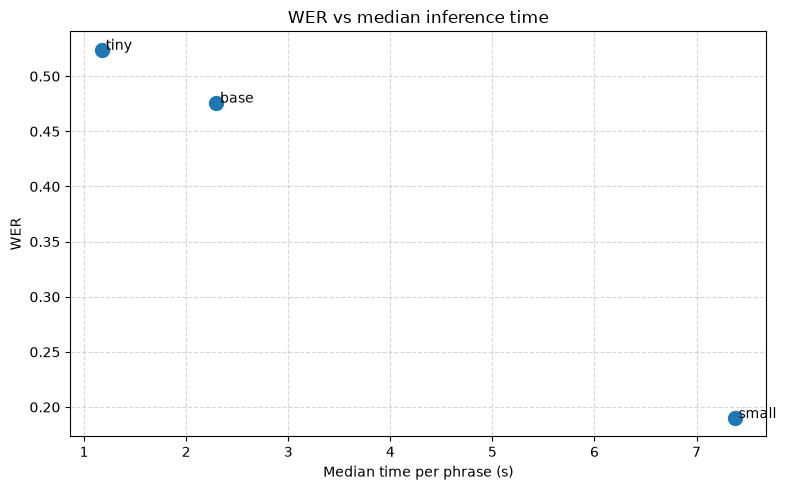

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(summary["median_time_s"], summary["WER"], s=100)
for _, row in summary.iterrows():
    plt.text(row["median_time_s"], row["WER"], " " + row["model"])
plt.title("WER vs median inference time")
plt.xlabel("Median time per phrase (s)")
plt.ylabel("WER")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("../results/wer_vs_time.png", dpi=150, bbox_inches="tight")
plt.show()